In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética de los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [2]:
# Cargar el dataset desde la carpeta raw
df = pd.read_csv('../data/raw/ev_battery_health.csv')

print("--- INFORMACIÓN GENERAL DEL DATASET ---")
print(f"Número total de filas (muestras): {df.shape[0]}")
print(f"Número total de columnas (variables): {df.shape[1]}\n")

# Estructura del conjunto de datos y tipos de datos
print(df.info())

--- INFORMACIÓN GENERAL DEL DATASET ---
Número total de filas (muestras): 50000
Número total de columnas (variables): 35

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 35 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   battery_id                      50000 non-null  object 
 1   observation_id                  50000 non-null  object 
 2   chemistry                       46541 non-null  object 
 3   manufacturer                    47539 non-null  object 
 4   vehicle_model                   46485 non-null  object 
 5   pack_capacity_kwh               47698 non-null  float64
 6   manufacture_date                48090 non-null  object 
 7   observation_date                47784 non-null  object 
 8   battery_age_days                46998 non-null  float64
 9   cycle_count                     47731 non-null  float64
 10  climate_zone                    

In [3]:
# Visualizar las primeras 5 filas
display(df.head())

# Conteo de valores nulos o faltantes por columna
missing_values = df.isnull().sum()
print("--- VALORES FALTANTES POR VARIABLE ---")
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "No hay valores nulos en el dataset.")

,battery_id,observation_id,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,manufacture_date,observation_date,battery_age_days,cycle_count,...,peak_temp_during_fast_charge_c,capacity_fade_pct,service_count,last_service_date,bms_firmware_version,recall_flag,state_of_health_pct,remaining_useful_life_cycles,failure_risk_label,degradation_category
0,BATT_01748,OBS_033554,LMO,StormCell,Crossover-X2,48.5,2022-11-23,2024-10-16,693.0,991.0,...,-1.3,19.13,4.0,2023-12-25,BMS_v2.1,0.0,80.87,0,High,Normal
1,BATT_00491,OBS_009428,LFP,VoltaCore,Sedan-E1,61.5,2023-03-06,2024-12-27,662.0,1535.0,...,5.3,8.19,0.0,NaN,BMS_v3.2,0.0,91.81,1739,Low,Normal
2,BATT_00011,OBS_000200,LFP,IonFlux,Van-E4,73.1,2025-06-24,2026-02-10,NaN,407.0,...,21.3,2.52,0.0,NaN,NaN,0.0,97.48,3248,Low,Normal
3,BATT_00651,OBS_012448,NMC,Amperion,NaN,75.6,2022-08-13,2022-09-15,33.0,29.0,...,20.8,0.82,0.0,NaN,BMS_v3.5,0.0,99.18,1375,Low,Normal
4,BATT_02054,OBS_039490,NCA,VoltaCore,Hatch-E3,92.7,2024-09-27,2026-03-01,520.0,324.0,...,40.1,8.14,0.0,NaN,BMS_v2.1,0.0,91.86,715,Low,Normal


--- VALORES FALTANTES POR VARIABLE ---
chemistry                          3459
manufacturer                       2461
vehicle_model                      3515
pack_capacity_kwh                  2302
manufacture_date                   1910
observation_date                   2216
battery_age_days                   3002
cycle_count                        2269
climate_zone                       2719
avg_daily_distance_km              2118
avg_charging_power_kw              2140
fast_charge_ratio                  3405
avg_depth_of_discharge_pct         2832
avg_state_of_charge_pct            3138
charge_cycles_per_month            2054
total_energy_throughput_kwh        3370
avg_ambient_temp_c                 3282
humidity_pct                       2737
altitude_m                         2322
internal_resistance_mohm           2104
voltage_avg_v                      2807
current_avg_a                      2487
charge_time_avg_min                2091
peak_temp_during_fast_charge_c     2128
c

Variable objetivo identificada: 'failure_risk_label'

                    Cantidad  Porcentaje (%)
failure_risk_label                          
Low                    42735          85.470
Medium                  4409           8.818
High                    2856           5.712


C:\Users\User\AppData\Local\Temp\ipykernel_32704\2158646663.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=target_col, palette='viridis')


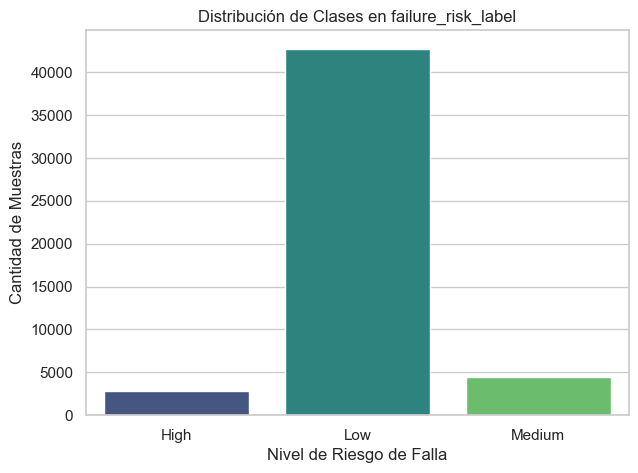

In [4]:
# Verificar el nombre exacto de la columna target si varía en mayúsculas/minúsculas
# Ajusta 'failure_risk' si en tu dataframe aparece en otro formato (ej. 'Failure_Risk')

target_col = [col for col in df.columns if 'failure' in col.lower() or 'risk' in col.lower()][0]

print(f"Variable objetivo identificada: '{target_col}'\n")

# Conteo y proporción de clases
counts = df[target_col].value_counts()
proportions = df[target_col].value_counts(normalize=True) * 100

df_target = pd.DataFrame({'Cantidad': counts, 'Porcentaje (%)': proportions})
print(df_target)

# Gráfico de la distribución de clases
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x=target_col, palette='viridis')
plt.title(f'Distribución de Clases en {target_col}')
plt.xlabel('Nivel de Riesgo de Falla')
plt.ylabel('Cantidad de Muestras')
plt.show()

In [5]:
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. Copia del dataframe para preprocesamiento
df_proc = df.copy()

# 2. Eliminar columnas de identificadores y fechas brutas que no aportan al patrón general
cols_to_drop = ['battery_id', 'observation_id', 'manufacture_date', 'observation_date', 'last_service_date']
df_proc = df_proc.drop(columns=[col for col in cols_to_drop if col in df_proc.columns])

# 3. Mapeo explícito de la variable objetivo
target_map = {'Low': 0, 'Medium': 1, 'High': 2}
df_proc['failure_risk_label'] = df_proc['failure_risk_label'].map(target_map)

# 4. Separación en Características (X) y Target (y)
X = df_proc.drop(columns=['failure_risk_label', 'degradation_category', 'state_of_health_pct', 'remaining_useful_life_cycles'], errors='ignore')
y = df_proc['failure_risk_label']

# 5. Tratamiento de Valores Faltantes (Imputación)
# Variables numéricas -> Imputación con la MEDIANA
num_cols = X.select_dtypes(include=['float64', 'int64']).columns
for col in num_cols:
    X[col] = X[col].fillna(X[col].median())

# Variables categóricas -> Imputación con la MODA
cat_cols = X.select_dtypes(include=['object', 'category']).columns
for col in cat_cols:
    X[col] = X[col].fillna(X[col].mode()[0])

# 6. Codificación de Variables Categóricas (One-Hot Encoding)
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)

# 7. División Train-Test (80% Entrenamiento/Validación, 20% Evaluación Final Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Dimensión de X_train: {X_train.shape}")
print(f"Dimensión de X_test:  {X_test.shape}")

# 8. Guardar conjuntos procesados en la carpeta data/processed
os.makedirs('../data/processed', exist_ok=True)
X_train.to_csv('../data/processed/X_train.csv', index=False)
X_test.to_csv('../data/processed/X_test.csv', index=False)
y_train.to_csv('../data/processed/y_train.csv', index=False)
y_test.to_csv('../data/processed/y_test.csv', index=False)

print("\n¡Datos limpios, preprocesados y guardados con éxito en 'data/processed/'!")

Dimensión de X_train: (40000, 46)
Dimensión de X_test:  (10000, 46)

¡Datos limpios, preprocesados y guardados con éxito en 'data/processed/'!
